# Review 2 · Method 2 — Association Rule Mining of Delinquency Warning Patterns
**Project:** IntelliCredit — FinTech Micro-Lending Risk & Alternative Credit Scoring Engine
**Rubric:** Method 2 — Data preparation & implementation (4) · Evaluation & interpretation (3)

### Business question
*"Which **combinations** of behavioural warning signs appear together in borrowers who default — far more often than chance?"*

The Review 1 model gives one probability per applicant. Underwriters and collections teams also need **human-readable red-flag rules** such as *"new gig worker AND late utility payer AND thin savings → 3× the normal default rate"*. Association rule mining finds exactly these multi-factor patterns.

### Key measures (rule A ⇒ B)
| Measure | Formula | Meaning here |
|---|---|---|
| Support | P(A ∩ B) | share of all borrowers that show the whole pattern |
| Confidence | P(B \| A) | default rate among borrowers who show A |
| Lift | P(B \| A) / P(B) | how many times more likely default is than average (> 1 = positive association) |
| Leverage | P(A ∩ B) − P(A)P(B) | extra co-occurrence beyond independence |
| Conviction | (1 − P(B)) / (1 − conf) | how much more often A would be "wrong" if A and B were independent |

In [1]:
import os, sys, json, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

ROOT = os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
from src.config import DATA_DIR, MODELS_DIR, RANDOM_STATE, TEST_SIZE

## Part A — Data preparation
### A1. Borrower table and the same train/test split as Review 1
Rules are **mined on the training borrowers only** and then checked on the unseen test borrowers — the same 80/20 stratified split (seed 42) used by the Review 1 models, so the two methods can be compared on identical people.

In [2]:
b = pd.read_csv(os.path.join(DATA_DIR, 'borrower_profiles.csv'))
b['loan_to_income'] = b['loan_amount_requested'] / b['avg_monthly_income']
b['repayment_ratio'] = np.where(b['previous_micro_loans'] > 0, b['previous_loans_repaid_on_time'] / b['previous_micro_loans'].clip(lower=1), np.nan)

train_idx, test_idx = train_test_split(b.index, test_size=TEST_SIZE, stratify=b['loan_default_status'], random_state=RANDOM_STATE)
tr, te = b.loc[train_idx], b.loc[test_idx]
BASE_RATE = tr['loan_default_status'].mean()
print(f'train {len(tr):,} borrowers | test {len(te):,} | train default rate {BASE_RATE:.2%}')

train 24,000 borrowers | test 6,000 | train default rate 7.87%


### A2. Discretisation — turning numbers into warning flags ("items")
Apriori works on **baskets of items**, so every borrower becomes a basket of yes/no flags. Thresholds are business-readable and, where a quantile is used, the quantile is computed on the **training rows** (no information from the test set). The definitions are saved to `models/arm_item_definitions.json` so the dashboard can flag a new applicant exactly the same way.

In [3]:
q = tr.select_dtypes(include='number').quantile
ITEM_DEFS = [
    # name,                     column,                      op,   threshold,                         description
    ('INCOME_VOLATILE',          'income_volatility_index',   '>=', q(0.75)['income_volatility_index'], 'income volatility in the top 25%'),
    ('DECLINING_INCOME',         'income_trend_slope',        '<',  0.0,                                 '12-month income trend is negative'),
    ('LOW_INCOME',               'avg_monthly_income',        '<=', q(0.25)['avg_monthly_income'],      'average monthly income in the bottom 25%'),
    ('LATE_UTILITY_PAYER',       'utility_on_time_count',     '<=', q(0.25)['utility_on_time_count'],   'paid at most this many of 12 utility bills on time'),
    ('LONG_UTILITY_DELAYS',      'max_utility_delay_days',    '>=', q(0.75)['max_utility_delay_days'],  'worst utility delay in the top 25%'),
    ('HIGH_BNPL_BURDEN',         'debt_to_inflow_ratio',      '>=', q(0.75)['debt_to_inflow_ratio'],    'BNPL spend / income in the top 25%'),
    ('LOW_SAVINGS_BUFFER',       'savings_buffer_ratio',      '<=', q(0.25)['savings_buffer_ratio'],    'month-end balance / spending in the bottom 25%'),
    ('NEW_GIG_WORKER',           'gig_tenure_months',         '<',  6,                                   'less than 6 months on the gig platform'),
    ('LOW_APP_ENGAGEMENT',       'avg_app_logins',            '<=', q(0.25)['avg_app_logins'],          'app logins in the bottom 25%'),
    ('IRREGULAR_RECHARGE',       'avg_days_between_recharges','>=', q(0.75)['avg_days_between_recharges'], 'longest gaps between mobile recharges (top 25%)'),
    ('LARGE_LOAN_VS_INCOME',     'loan_to_income',            '>=', q(0.75)['loan_to_income'],          'loan amount / monthly income in the top 25%'),
    ('WEAK_REPAYMENT_HISTORY',   'repayment_ratio',           '<',  0.7,                                 'repaid < 70% of previous micro-loans on time'),
    ('NO_CREDIT_HISTORY',        'previous_micro_loans',      '==', 0,                                   'no previous micro-loans'),
    ('HIGH_INTEREST_LOAN',       'interest_rate_annual',      '>=', 24.0,                                'annual interest rate of 24% or more'),
    ('YOUNG_BORROWER',           'age',                       '<',  25,                                  'younger than 25'),
    ('MANY_DEPENDENTS',          'num_dependents',            '>=', 3,                                   '3 or more dependents'),
    ('NO_BANK_ACCOUNT',          'has_bank_account',          '==', 0,                                   'no formal bank account'),
    ('METRO_RESIDENT',           'location_type',             '==', 'Metro',                             'lives in a metro city'),
    ('RURAL_RESIDENT',           'location_type',             '==', 'Rural',                             'lives in a rural area'),
]

OPS = {'>=': np.greater_equal, '<=': np.less_equal, '<': np.less, '>': np.greater, '==': np.equal}

def to_basket(df):
    basket = pd.DataFrame(index=df.index)
    for name, col, op, thr, _ in ITEM_DEFS:
        values = df[col]
        basket[name] = OPS[op](values, thr).fillna(False) if values.dtype != object else (values == thr)
    basket['DEFAULT'] = df['loan_default_status'] == 1
    return basket.astype(bool)

basket_tr, basket_te = to_basket(tr), to_basket(te)
item_defs_df = pd.DataFrame(ITEM_DEFS, columns=['item', 'column', 'op', 'threshold', 'description'])
display(item_defs_df.assign(threshold=item_defs_df['threshold'].map(lambda v: round(v, 3) if isinstance(v, float) else v)))
print('basket shape (train):', basket_tr.shape, '| avg flags per borrower:', round(basket_tr.drop(columns='DEFAULT').sum(axis=1).mean(), 2))

,item,column,op,threshold,description
0,INCOME_VOLATILE,income_volatility_index,>=,0.334,income volatility in the top 25%
1,DECLINING_INCOME,income_trend_slope,<,0.0,12-month income trend is negative
2,LOW_INCOME,avg_monthly_income,<=,19484.543,average monthly income in the bottom 25%
3,LATE_UTILITY_PAYER,utility_on_time_count,<=,7.0,paid at most this many of 12 utility bills on ...
4,LONG_UTILITY_DELAYS,max_utility_delay_days,>=,32.0,worst utility delay in the top 25%
5,HIGH_BNPL_BURDEN,debt_to_inflow_ratio,>=,0.143,BNPL spend / income in the top 25%
6,LOW_SAVINGS_BUFFER,savings_buffer_ratio,<=,0.482,month-end balance / spending in the bottom 25%
7,NEW_GIG_WORKER,gig_tenure_months,<,6,less than 6 months on the gig platform
8,LOW_APP_ENGAGEMENT,avg_app_logins,<=,15.92,app logins in the bottom 25%
9,IRREGULAR_RECHARGE,avg_days_between_recharges,>=,29.08,longest gaps between mobile recharges (top 25%)


basket shape (train): (24000, 20) | avg flags per borrower: 5.22


### A3. Single-item view — how risky is each flag on its own?
Before looking for combinations, check each flag's frequency (support) and its own default rate. A flag's **lift** on its own is the yardstick a multi-factor rule has to beat.

,support,default rate,lift
NEW_GIG_WORKER,0.280,0.129,1.645
LATE_UTILITY_PAYER,0.338,0.127,1.608
LOW_APP_ENGAGEMENT,0.254,0.125,1.589
INCOME_VOLATILE,0.250,0.125,1.587
LOW_SAVINGS_BUFFER,0.250,0.109,1.380
DECLINING_INCOME,0.506,0.095,1.203
LONG_UTILITY_DELAYS,0.250,0.094,1.201
METRO_RESIDENT,0.301,0.091,1.158
LARGE_LOAN_VS_INCOME,0.250,0.088,1.123
YOUNG_BORROWER,0.190,0.085,1.085


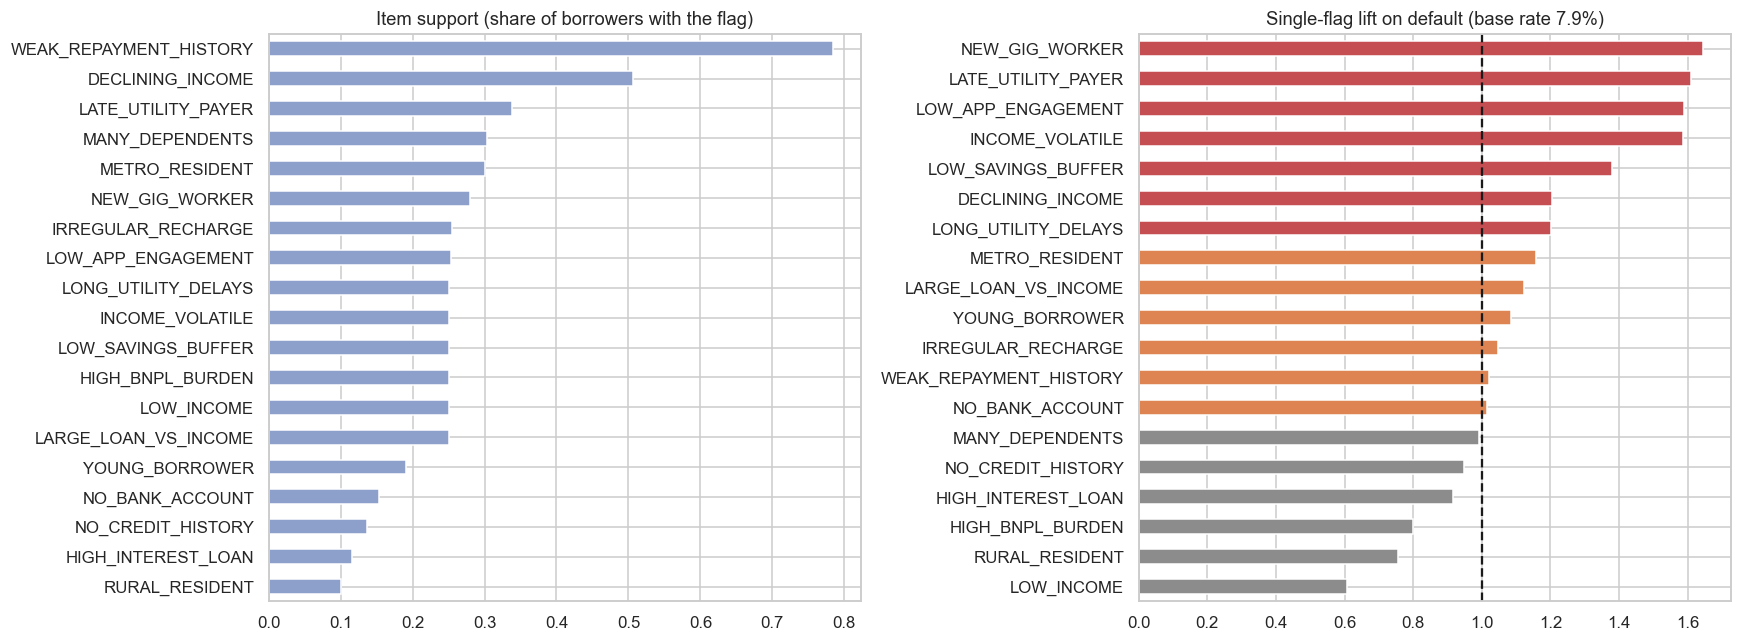

In [4]:
single = pd.DataFrame({
    'support': basket_tr.drop(columns='DEFAULT').mean(),
    'default rate': [tr.loc[basket_tr[c], 'loan_default_status'].mean() for c in basket_tr.columns if c != 'DEFAULT'],
})
single['lift'] = single['default rate'] / BASE_RATE
single = single.sort_values('lift', ascending=False)
display(single.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
single['support'].sort_values().plot.barh(ax=axes[0], color='#8da0cb'); axes[0].set_title('Item support (share of borrowers with the flag)')
colors = ['#c44e52' if v > 1.2 else '#dd8452' if v > 1 else '#8c8c8c' for v in single['lift'].sort_values()]
single['lift'].sort_values().plot.barh(ax=axes[1], color=colors); axes[1].axvline(1, c='k', ls='--')
axes[1].set_title(f'Single-flag lift on default (base rate {BASE_RATE:.1%})')
plt.tight_layout(); plt.show()

## Part B — Implementation: Apriori vs FP-Growth
* **Apriori** grows itemsets level by level and prunes any itemset whose subset is infrequent (the *downward-closure* property).
* **FP-Growth** compresses the baskets into a prefix tree and mines it without generating candidates — usually much faster.

Both must return **identical** frequent itemsets; only the speed differs. `min_support = 0.5%` (≈ 120 training borrowers) keeps rare-but-dangerous combinations (defaulters are only 7.9% of borrowers), and itemsets are capped at 4 items so rules stay readable.

In [5]:
MIN_SUPPORT, MAX_LEN = 0.005, 4

t0 = time.perf_counter(); fi_ap = apriori(basket_tr, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_ap = time.perf_counter() - t0
t0 = time.perf_counter(); fi_fp = fpgrowth(basket_tr, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_fp = time.perf_counter() - t0

same = set(map(frozenset, fi_ap['itemsets'])) == set(map(frozenset, fi_fp['itemsets']))
print(f'Apriori : {len(fi_ap):,} frequent itemsets in {t_ap:.2f}s')
print(f'FP-Growth: {len(fi_fp):,} frequent itemsets in {t_fp:.2f}s  ({t_ap / t_fp:.1f}x faster)')
print('Identical itemsets:', same)
fi_ap['length'] = fi_ap['itemsets'].apply(len)
display(fi_ap.groupby('length').size().rename('itemsets').to_frame().T)

Apriori : 2,852 frequent itemsets in 0.65s
FP-Growth: 2,852 frequent itemsets in 0.98s  (0.7x faster)
Identical itemsets: True


length,1,2,3,4
itemsets,20,188,943,1701


,min_support,itemsets,apriori s,fpgrowth s
0,0.050,215,0.074,0.574
1,0.020,773,0.217,0.648
2,0.010,1649,0.383,0.876
3,0.005,2852,0.621,1.127
4,0.003,3732,0.677,1.020


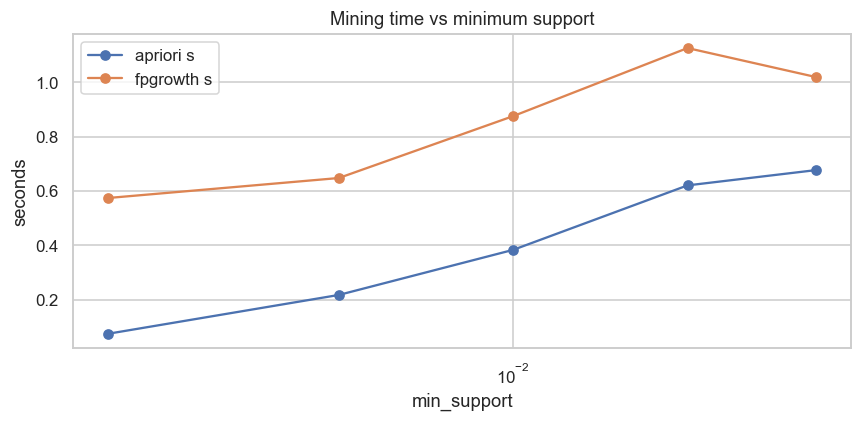

In [6]:
# Runtime as min_support falls - the cost of looking for rarer patterns
timing = []
for ms in [0.05, 0.02, 0.01, 0.005, 0.003]:
    t0 = time.perf_counter(); n_ap = len(apriori(basket_tr, min_support=ms, use_colnames=True, max_len=MAX_LEN)); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); n_fp = len(fpgrowth(basket_tr, min_support=ms, use_colnames=True, max_len=MAX_LEN)); tf = time.perf_counter() - t0
    timing.append({'min_support': ms, 'itemsets': n_ap, 'apriori s': ta, 'fpgrowth s': tf})
timing = pd.DataFrame(timing)
display(timing.round(3))
ax = timing.plot(x='min_support', y=['apriori s', 'fpgrowth s'], marker='o', logx=True, figsize=(8, 4), title='Mining time vs minimum support')
ax.invert_xaxis(); ax.set_ylabel('seconds'); plt.tight_layout(); plt.show()

### B1. Generating rules and keeping the useful ones
From the frequent itemsets, `association_rules` produces every rule A ⇒ B. We keep **warning rules** — rules whose consequent is exactly `{DEFAULT}` — that pass three filters:
* **lift ≥ 1.5** (at least 50% riskier than average),
* **support ≥ 0.5%** of borrowers (pattern common enough to act on),
* **statistically significant**: one-sided Fisher exact test on the 2×2 table (pattern vs default), Bonferroni-corrected for the number of rules tested.

In [7]:
rules_all = association_rules(fi_fp, metric='lift', min_threshold=1.0, num_itemsets=len(basket_tr))
print(f'{len(rules_all):,} rules with lift >= 1 among all items')

warn = rules_all[rules_all['consequents'] == frozenset({'DEFAULT'})].copy()
warn['antecedent'] = warn['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
warn['n_items'] = warn['antecedents'].apply(len)

def fisher_p(ante, basket):
    has = basket[list(ante)].all(axis=1)
    d = basket['DEFAULT']
    table = [[(has & d).sum(), (has & ~d).sum()], [(~has & d).sum(), (~has & ~d).sum()]]
    return fisher_exact(table, alternative='greater')[1]

warn['p_value'] = warn['antecedents'].apply(lambda a: fisher_p(a, basket_tr))
warn['p_bonferroni'] = (warn['p_value'] * len(warn)).clip(upper=1)
print(f'{len(warn):,} candidate warning rules (consequent = DEFAULT)')

strong = warn[(warn['lift'] >= 1.5) & (warn['support'] >= MIN_SUPPORT) & (warn['p_bonferroni'] < 0.05)].copy()
print(f'{len(strong):,} pass lift >= 1.5, support >= {MIN_SUPPORT:.1%}, Bonferroni p < 0.05')

21,684 rules with lift >= 1 among all items


242 candidate warning rules (consequent = DEFAULT)
170 pass lift >= 1.5, support >= 0.5%, Bonferroni p < 0.05


### B2. Removing redundant rules
If *{A, B} ⇒ DEFAULT* is no better than *{A} ⇒ DEFAULT*, the extra condition B adds nothing. A rule is kept only if its confidence beats **every** one of its sub-rules by at least 5% (relative) — a "productive rule" filter that leaves a short list an underwriter can actually use.

In [8]:
conf_lookup = dict(zip(warn['antecedents'], warn['confidence']))

def is_productive(ante, conf):
    for k in range(1, len(ante)):
        for sub in itertools.combinations(ante, k):
            sub_conf = conf_lookup.get(frozenset(sub), BASE_RATE)
            if conf < sub_conf * 1.05:
                return False
    return conf >= BASE_RATE * 1.05

strong['productive'] = [is_productive(a, c) for a, c in zip(strong['antecedents'], strong['confidence'])]
final_rules = strong[strong['productive']].sort_values('lift', ascending=False).reset_index(drop=True)
print(f'{len(strong):,} strong rules -> {len(final_rules):,} non-redundant rules')
cols = ['antecedent', 'n_items', 'support', 'confidence', 'lift', 'leverage', 'conviction', 'p_bonferroni']
display(final_rules[cols].head(20).style.format({'support': '{:.3%}', 'confidence': '{:.1%}', 'lift': '{:.2f}', 'leverage': '{:.4f}', 'conviction': '{:.3f}', 'p_bonferroni': '{:.1e}'}).background_gradient(subset=['lift'], cmap='Reds'))

170 strong rules -> 93 non-redundant rules


,antecedent,n_items,support,confidence,lift,leverage,conviction,p_bonferroni
0,DECLINING_INCOME + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.771%,22.0%,2.79,0.0049,1.181,1.2e-36
1,DECLINING_INCOME + LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER,3,0.871%,21.3%,2.71,0.0055,1.171,1.0e-39
2,INCOME_VOLATILE + LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER,3,0.596%,21.3%,2.71,0.0038,1.171,2.2e-26
3,DECLINING_INCOME + LOW_APP_ENGAGEMENT + LOW_SAVINGS_BUFFER,3,0.683%,20.8%,2.64,0.0042,1.163,4.1e-29
4,LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.742%,20.7%,2.63,0.0046,1.162,1.3e-31
5,DECLINING_INCOME + INCOME_VOLATILE + LOW_SAVINGS_BUFFER,3,0.604%,20.2%,2.57,0.0037,1.155,2.6e-24
6,LATE_UTILITY_PAYER + LOW_APP_ENGAGEMENT + LOW_SAVINGS_BUFFER,3,0.625%,20.2%,2.56,0.0038,1.154,4.7e-25
7,INCOME_VOLATILE + LATE_UTILITY_PAYER + METRO_RESIDENT,3,0.696%,19.5%,2.47,0.0041,1.144,3.0e-26
8,INCOME_VOLATILE + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.542%,19.5%,2.47,0.0032,1.144,4.7e-20
9,LATE_UTILITY_PAYER + LOW_APP_ENGAGEMENT + METRO_RESIDENT,3,0.742%,19.2%,2.44,0.0044,1.140,3.0e-27


## Part C — Evaluation
### C1. Do the rules hold on borrowers they have never seen?
Mining many combinations always finds *some* patterns by chance. Re-computing support, confidence and lift on the **test borrowers** shows which rules are real.

100% of rules keep lift >= 1.3 on the test set | correlation train-vs-test lift = 0.61
median lift: train 2.03 -> test 1.89 (shrinkage is expected - the train lift is partly selection luck)


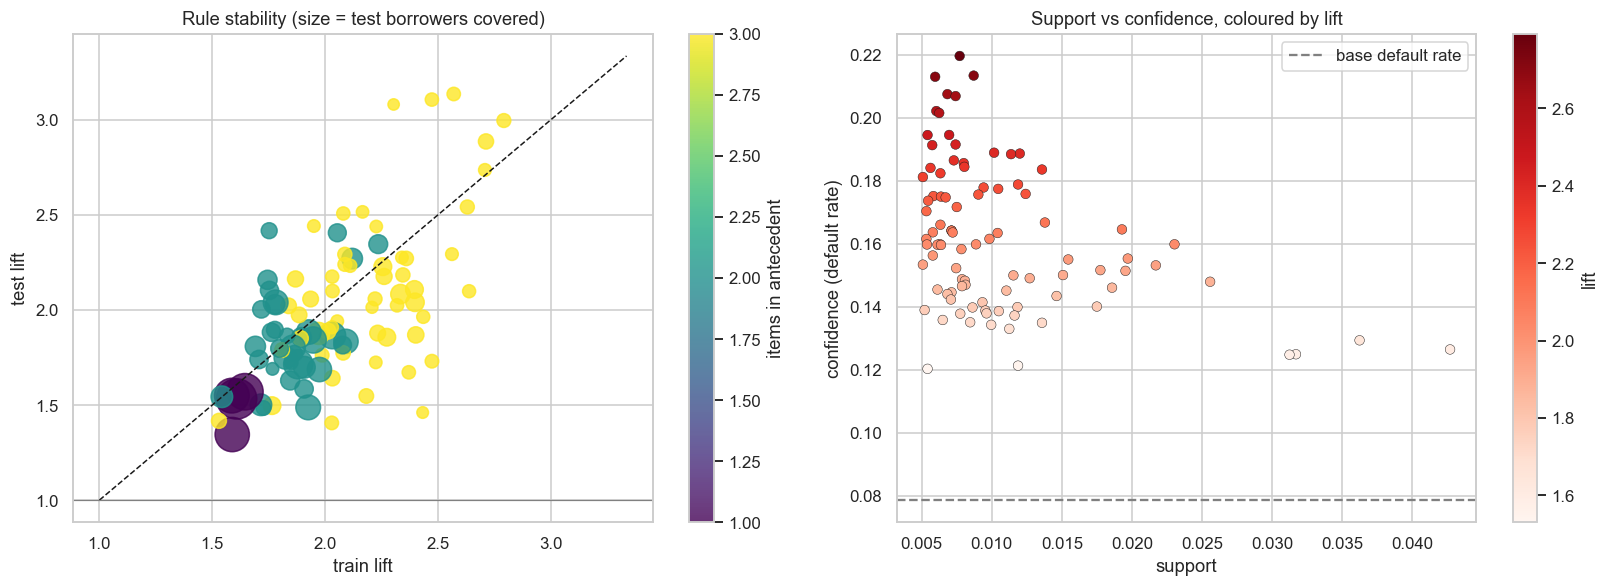

In [9]:
def eval_rule(ante, basket):
    has = basket[list(ante)].all(axis=1)
    n = has.sum()
    conf = basket.loc[has, 'DEFAULT'].mean() if n else np.nan
    return pd.Series({'test_support': (has & basket['DEFAULT']).mean(), 'test_coverage': has.mean(),
                      'test_confidence': conf, 'test_lift': conf / basket['DEFAULT'].mean() if n else np.nan, 'test_n': n})

final_rules = pd.concat([final_rules, final_rules['antecedents'].apply(lambda a: eval_rule(a, basket_te))], axis=1)
final_rules['holds_on_test'] = final_rules['test_lift'] >= 1.3

r = np.corrcoef(final_rules['lift'], final_rules['test_lift'])[0, 1]
print(f'{final_rules["holds_on_test"].mean():.0%} of rules keep lift >= 1.3 on the test set | correlation train-vs-test lift = {r:.2f}')
print(f'median lift: train {final_rules["lift"].median():.2f} -> test {final_rules["test_lift"].median():.2f} (shrinkage is expected - the train lift is partly selection luck)')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sc = axes[0].scatter(final_rules['lift'], final_rules['test_lift'], c=final_rules['n_items'], s=final_rules['test_n'] / 3, cmap='viridis', alpha=0.8)
lim = [1, max(final_rules['lift'].max(), final_rules['test_lift'].max()) + 0.2]
axes[0].plot(lim, lim, 'k--', lw=1); axes[0].axhline(1, c='grey', lw=0.8)
axes[0].set_xlabel('train lift'); axes[0].set_ylabel('test lift'); axes[0].set_title('Rule stability (size = test borrowers covered)')
plt.colorbar(sc, ax=axes[0], label='items in antecedent')
sc2 = axes[1].scatter(final_rules['support'], final_rules['confidence'], c=final_rules['lift'], cmap='Reds', s=40, edgecolor='k', lw=0.3)
axes[1].axhline(BASE_RATE, c='grey', ls='--', label='base default rate'); axes[1].legend()
axes[1].set_xlabel('support'); axes[1].set_ylabel('confidence (default rate)'); axes[1].set_title('Support vs confidence, coloured by lift')
plt.colorbar(sc2, ax=axes[1], label='lift')
plt.tight_layout(); plt.show()

In [10]:
validated = final_rules[final_rules['holds_on_test']].sort_values(['test_lift', 'lift'], ascending=False).reset_index(drop=True)
show = validated[['antecedent', 'n_items', 'support', 'confidence', 'lift', 'test_coverage', 'test_confidence', 'test_lift']].head(15)
display(show.style.format({'support': '{:.2%}', 'confidence': '{:.1%}', 'lift': '{:.2f}', 'test_coverage': '{:.2%}', 'test_confidence': '{:.1%}', 'test_lift': '{:.2f}'}).background_gradient(subset=['test_lift'], cmap='Reds'))

,antecedent,n_items,support,confidence,lift,test_coverage,test_confidence,test_lift
0,DECLINING_INCOME + INCOME_VOLATILE + LOW_SAVINGS_BUFFER,3,0.60%,20.2%,2.57,3.85%,24.7%,3.14
1,INCOME_VOLATILE + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.54%,19.5%,2.47,3.75%,24.4%,3.11
2,DECLINING_INCOME + LARGE_LOAN_VS_INCOME + LOW_SAVINGS_BUFFER,3,0.51%,18.1%,2.30,2.75%,24.2%,3.08
3,DECLINING_INCOME + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.77%,22.0%,2.79,4.10%,23.6%,3.00
4,DECLINING_INCOME + LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER,3,0.87%,21.3%,2.71,4.92%,22.7%,2.89
5,INCOME_VOLATILE + LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER,3,0.60%,21.3%,2.71,3.48%,21.5%,2.74
6,LATE_UTILITY_PAYER + LOW_SAVINGS_BUFFER + NEW_GIG_WORKER,3,0.74%,20.7%,2.63,4.17%,20.0%,2.54
7,DECLINING_INCOME + LONG_UTILITY_DELAYS + LOW_SAVINGS_BUFFER,3,0.53%,17.0%,2.17,3.28%,19.8%,2.52
8,DECLINING_INCOME + LARGE_LOAN_VS_INCOME + NEW_GIG_WORKER,3,0.58%,16.4%,2.08,3.72%,19.7%,2.51
9,DECLINING_INCOME + INCOME_VOLATILE + LARGE_LOAN_VS_INCOME,3,0.51%,15.3%,1.95,3.38%,19.2%,2.44


### C2. Which flags combine into dangerous pairs?
Heatmap of the **test-set default rate** for every pair of flags. Cells far above the base rate are interaction hot-spots; the diagonal is the flag on its own.

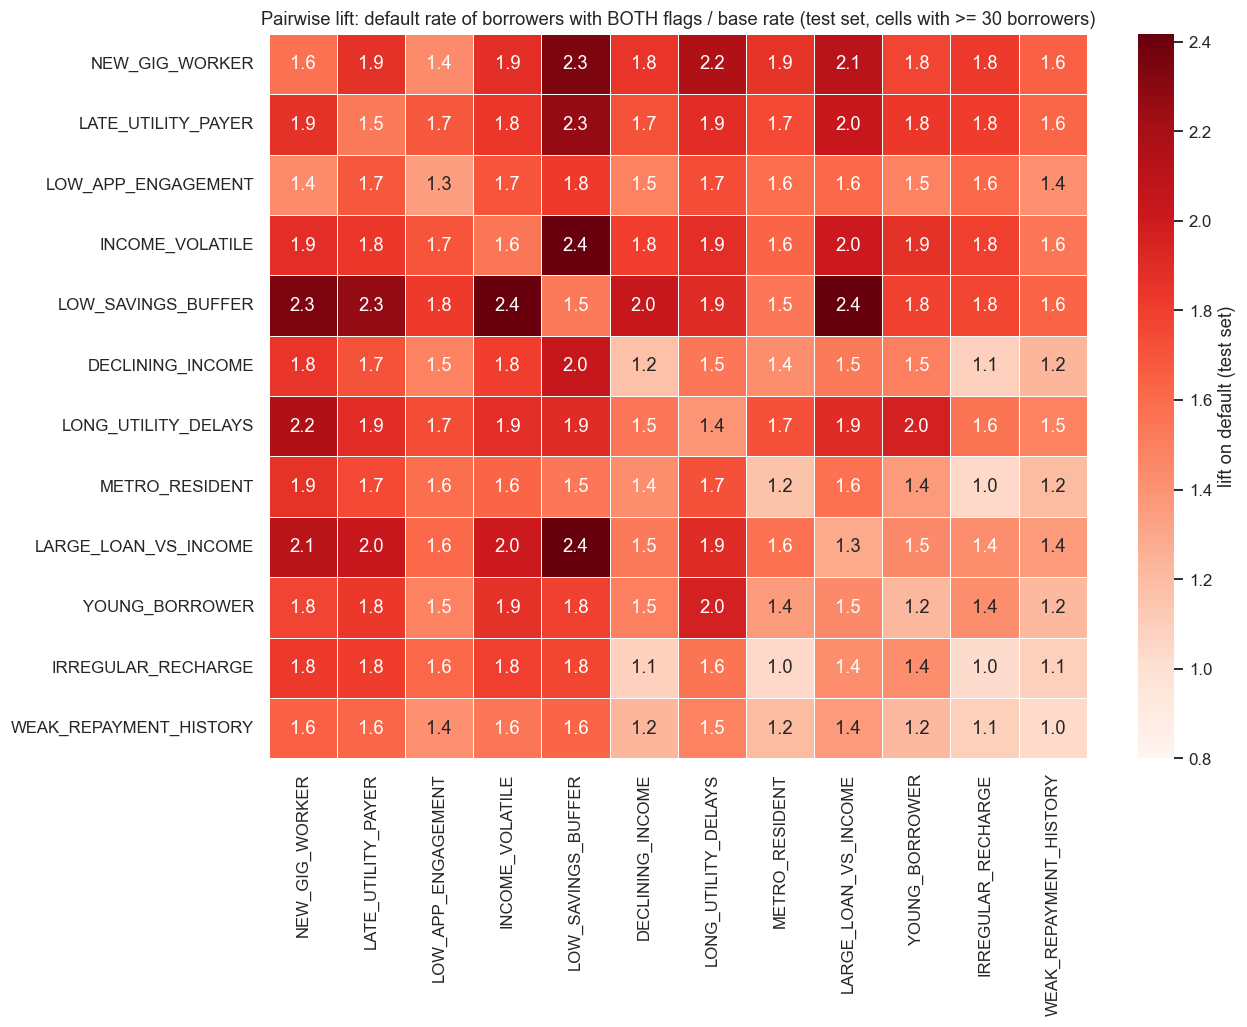

In [11]:
flags = [c for c in single.index[:12]]
pair = pd.DataFrame(index=flags, columns=flags, dtype=float)
for a in flags:
    for c in flags:
        has = basket_te[a] & basket_te[c]
        pair.loc[a, c] = basket_te.loc[has, 'DEFAULT'].mean() / basket_te['DEFAULT'].mean() if has.sum() >= 30 else np.nan
plt.figure(figsize=(12, 9.5))
sns.heatmap(pair.astype(float), annot=True, fmt='.1f', cmap='Reds', vmin=0.8, linewidths=0.4, cbar_kws={'label': 'lift on default (test set)'})
plt.title('Pairwise lift: default rate of borrowers with BOTH flags / base rate (test set, cells with >= 30 borrowers)')
plt.tight_layout(); plt.show()

### C3. Network of the strongest validated rules
Each red node is a warning flag; each grey node is a rule, sized by test-set lift. Flags that appear in many rules are the **hubs** of delinquency risk.

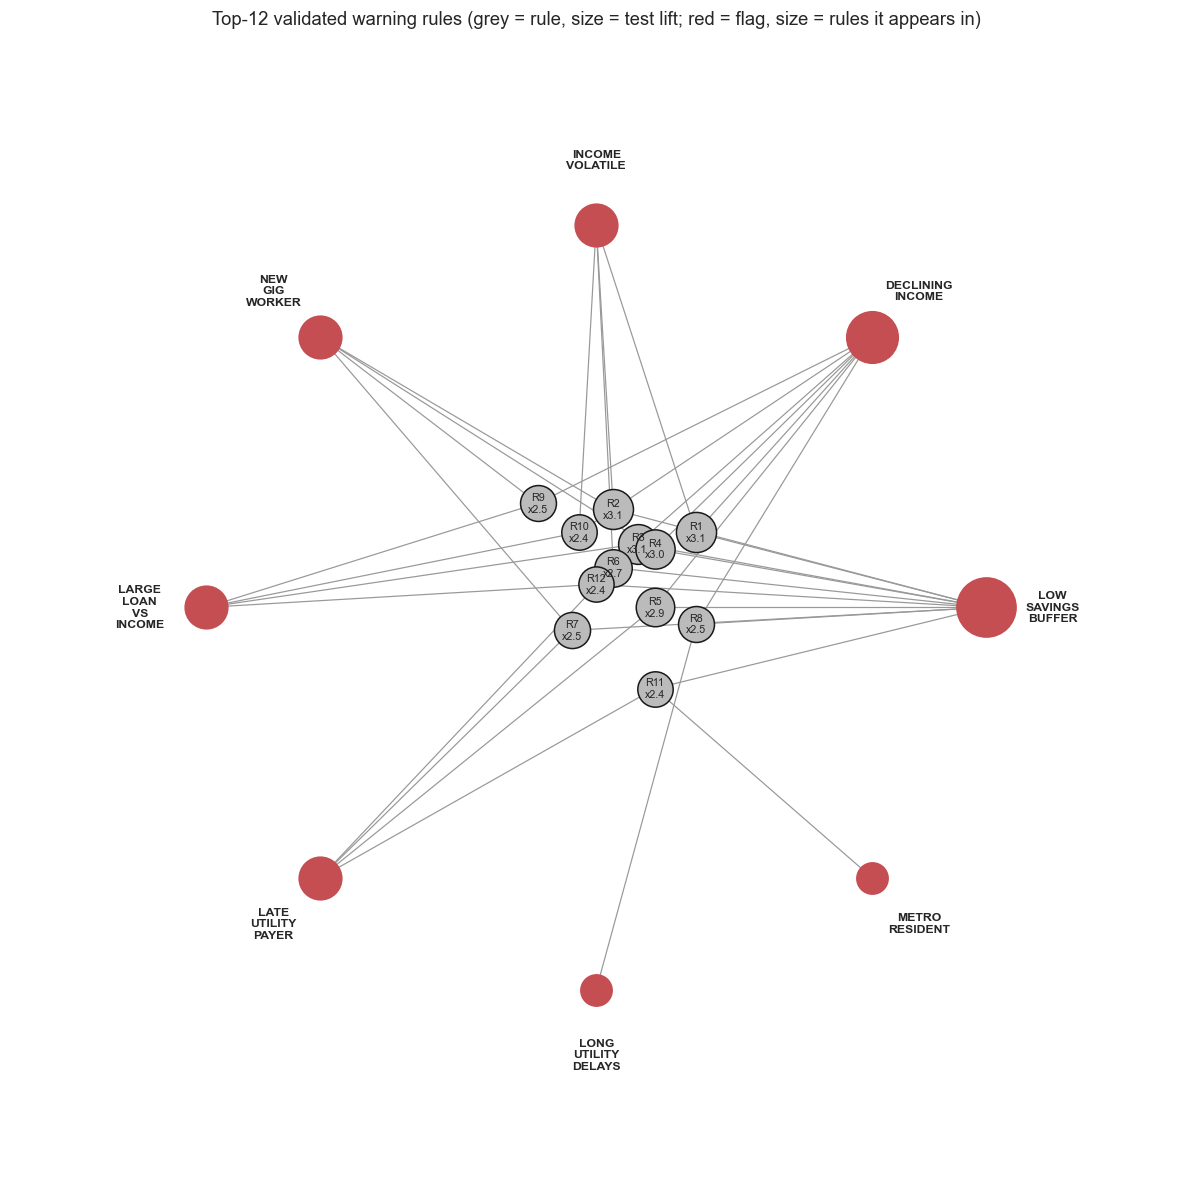

In [12]:
top = validated.head(12)
item_count = pd.Series([i for a in top['antecedents'] for i in a]).value_counts()
items_ = list(item_count.index)
angle = np.linspace(0, 2 * np.pi, len(items_), endpoint=False)
pos_items = {it: (np.cos(a) * 1.0, np.sin(a) * 1.0) for it, a in zip(items_, angle)}

fig, ax = plt.subplots(figsize=(11, 11))
for k, row in top.iterrows():
    xs = [pos_items[i][0] for i in row['antecedents']]
    ys = [pos_items[i][1] for i in row['antecedents']]
    rx, ry = np.mean(xs) * 0.45, np.mean(ys) * 0.45 + (k % 3 - 1) * 0.06
    for x_, y_ in zip(xs, ys):
        ax.plot([x_, rx], [y_, ry], color='#999999', lw=0.8, zorder=1)
    ax.scatter(rx, ry, s=row['test_lift'] * 220, color='#bbbbbb', edgecolor='k', zorder=2)
    ax.annotate(f'R{k + 1}\nx{row["test_lift"]:.1f}', (rx, ry), ha='center', va='center', fontsize=7, zorder=3)
for it, (x_, y_) in pos_items.items():
    ax.scatter(x_, y_, s=300 + item_count[it] * 120, color='#c44e52', zorder=3)
    ax.annotate(it.replace('_', '\n'), (x_ * 1.17, y_ * 1.17), ha='center', va='center', fontsize=8, fontweight='bold')
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.axis('off')
ax.set_title('Top-12 validated warning rules (grey = rule, size = test lift; red = flag, size = rules it appears in)')
plt.tight_layout(); plt.show()

### C4. From rules to an early-warning score — how good is it?
A simple, fully explainable score: **the number of validated warning rules an applicant triggers**. If the rules capture real risk, the default rate should rise steadily with that count. Its AUC is compared with the Review 1 ML model (≈ 0.74) and with the best achievable AUC on this data (the true default probability, ≈ 0.78).

,test borrowers,default rate,lift
0,3914,4.9%,0.62
1,863,9.4%,1.19
2,385,10.4%,1.32
3,219,17.4%,2.21
4,152,13.8%,1.76
5,106,11.3%,1.44
6+,361,24.7%,3.13


AUC of rule-count score (top 25 rules): 0.657  | true-PD ceiling: 0.781


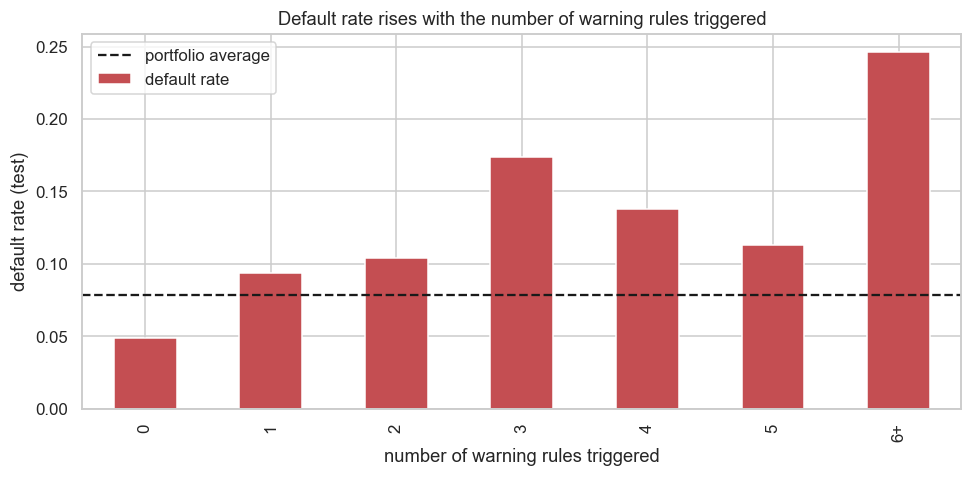

In [13]:
TOP_K = min(25, len(validated))
rule_set = list(validated['antecedents'].head(TOP_K))

def rule_hits(basket):
    return sum(basket[list(a)].all(axis=1).astype(int) for a in rule_set)

te_hits = rule_hits(basket_te)
auc_rules = roc_auc_score(basket_te['DEFAULT'], te_hits)
auc_oracle = roc_auc_score(te['loan_default_status'], te['default_probability_true'])

by_hits = pd.DataFrame({'hits': np.minimum(te_hits, 6), 'default': basket_te['DEFAULT']}).groupby('hits')['default'].agg(['count', 'mean'])
by_hits.index = [f'{i}' if i < 6 else '6+' for i in by_hits.index]
by_hits.columns = ['test borrowers', 'default rate']
by_hits['lift'] = by_hits['default rate'] / basket_te['DEFAULT'].mean()
display(by_hits.style.format({'default rate': '{:.1%}', 'lift': '{:.2f}'}))
print(f'AUC of rule-count score (top {TOP_K} rules): {auc_rules:.3f}  | true-PD ceiling: {auc_oracle:.3f}')

ax = by_hits['default rate'].plot.bar(color='#c44e52', figsize=(9, 4.5))
ax.axhline(basket_te['DEFAULT'].mean(), c='k', ls='--', label='portfolio average')
ax.set_xlabel('number of warning rules triggered'); ax.set_ylabel('default rate (test)'); ax.legend()
ax.set_title('Default rate rises with the number of warning rules triggered'); plt.tight_layout(); plt.show()

In [14]:
# A red-flag policy: send to manual review if >= N rules fire. What does it catch, and at what cost?
policy = []
for n_ in range(1, 6):
    flagged = te_hits >= n_
    policy.append({'rule': f'>= {n_} rules', 'flagged share': flagged.mean(),
                   'defaults caught (recall)': basket_te.loc[flagged, 'DEFAULT'].sum() / basket_te['DEFAULT'].sum(),
                   'default rate in flagged': basket_te.loc[flagged, 'DEFAULT'].mean(),
                   'default rate in the rest': basket_te.loc[~flagged, 'DEFAULT'].mean()})
policy = pd.DataFrame(policy).set_index('rule')
display(policy.style.format('{:.1%}'))

,flagged share,defaults caught (recall),default rate in flagged,default rate in the rest
rule,,,,
>= 1 rules,34.8%,59.5%,13.5%,4.9%
>= 2 rules,20.4%,42.4%,16.4%,5.7%
>= 3 rules,14.0%,33.9%,19.1%,6.0%
>= 4 rules,10.3%,25.8%,19.7%,6.5%
>= 5 rules,7.8%,21.4%,21.6%,6.7%


## Part D — Macro-conditioned rules: do the same flags hurt more in a downturn?
This links Method 2 to Method 1. Using the loan book from `src/portfolio_simulation.py`, each loan gets one more item — **STRESS_EXPOSED** if its life overlapped a month with a high macro stress index (≥ 1 SD, i.e. the COVID months) — and the outcome item is **default in the 2019–2024 panel**. If the lift of a warning flag is higher among stress-exposed loans, that flag is a *macro-sensitive* risk driver.

In [15]:
book = pd.read_csv(os.path.join(DATA_DIR, 'portfolio', 'loan_book.csv'))
pm = pd.read_csv(os.path.join(DATA_DIR, 'portfolio', 'portfolio_monthly.csv'), parse_dates=['date'])
stress_months = set(pm.loc[pm['stress_index'] >= 1, 'date'].dt.strftime('%Y-%m'))
print('high-stress months:', sorted(stress_months))

book = book[book['censored_at_window_end'] == 0].copy()        # completed loans only
start = pd.to_datetime(book['origination_month'])
end = pd.to_datetime(book['default_month'].fillna(book['maturity_month']))   # empty CSV cells load as NaN
stress_dates = pd.to_datetime(sorted(stress_months))
book['STRESS_EXPOSED'] = [bool(((stress_dates > s) & (stress_dates <= e)).any()) for s, e in zip(start, end)]

panel = b.set_index('borrower_id').loc[book['borrower_id']].reset_index()
panel_basket = to_basket(panel).drop(columns='DEFAULT')
panel_basket['STRESS_EXPOSED'] = book['STRESS_EXPOSED'].to_numpy()
panel_basket['PANEL_DEFAULT'] = book['defaulted_in_panel'].to_numpy() == 1
print(f'{len(panel_basket):,} completed loans | {panel_basket.STRESS_EXPOSED.mean():.1%} stress-exposed | panel default rate {panel_basket.PANEL_DEFAULT.mean():.2%}')

fi_panel = fpgrowth(panel_basket, min_support=0.003, use_colnames=True, max_len=3)
rules_panel = association_rules(fi_panel, metric='lift', min_threshold=1.0, num_itemsets=len(panel_basket))
rules_panel = rules_panel[rules_panel['consequents'] == frozenset({'PANEL_DEFAULT'})].copy()
rules_panel['antecedent'] = rules_panel['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
display(rules_panel.sort_values('lift', ascending=False)[['antecedent', 'support', 'confidence', 'lift']].head(10)
        .style.format({'support': '{:.2%}', 'confidence': '{:.1%}', 'lift': '{:.2f}'}))

high-stress months: ['2019-12', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08']


23,775 completed loans | 15.9% stress-exposed | panel default rate 6.25%


,antecedent,support,confidence,lift
4098,INCOME_VOLATILE + STRESS_EXPOSED,0.78%,19.9%,3.19
4080,LATE_UTILITY_PAYER + STRESS_EXPOSED,1.02%,18.8%,3.02
4086,NEW_GIG_WORKER + STRESS_EXPOSED,0.81%,18.4%,2.95
4110,LOW_APP_ENGAGEMENT + STRESS_EXPOSED,0.69%,17.6%,2.82
4388,LONG_UTILITY_DELAYS + STRESS_EXPOSED,0.64%,16.2%,2.60
4092,LOW_SAVINGS_BUFFER + STRESS_EXPOSED,0.64%,16.0%,2.55
4482,LARGE_LOAN_VS_INCOME + STRESS_EXPOSED,0.62%,15.7%,2.51
4074,DECLINING_INCOME + STRESS_EXPOSED,1.18%,14.8%,2.36
4104,METRO_RESIDENT + STRESS_EXPOSED,0.72%,14.5%,2.32
4566,STRESS_EXPOSED + YOUNG_BORROWER,0.42%,13.8%,2.21


In [16]:
rows = []
for flag in [c for c in panel_basket.columns if c not in ('STRESS_EXPOSED', 'PANEL_DEFAULT')]:
    for exposed in (False, True):
        grp = panel_basket[panel_basket['STRESS_EXPOSED'] == exposed]
        base = grp['PANEL_DEFAULT'].mean()
        has = grp[flag]
        if has.sum() >= 50:
            rows.append({'flag': flag, 'regime': 'stress-exposed' if exposed else 'normal', 'default rate with flag': grp.loc[has, 'PANEL_DEFAULT'].mean(), 'base': base})
regime = pd.DataFrame(rows)
piv = regime.pivot(index='flag', columns='regime', values='default rate with flag')
base_rates = regime.groupby('regime')['base'].first()
piv['extra default pts in stress'] = (piv['stress-exposed'] - base_rates['stress-exposed']) - (piv['normal'] - base_rates['normal'])
piv = piv.sort_values('extra default pts in stress', ascending=False)
print(f"base panel default rate: normal {base_rates['normal']:.2%}, stress-exposed {base_rates['stress-exposed']:.2%}")
display(piv.style.format('{:.2%}').background_gradient(subset=['extra default pts in stress'], cmap='RdYlGn_r'))

base panel default rate: normal 5.00%, stress-exposed 12.88%


regime,normal,stress-exposed,extra default pts in stress
flag,,,
INCOME_VOLATILE,7.58%,19.91%,4.45%
LATE_UTILITY_PAYER,8.23%,18.85%,2.74%
NEW_GIG_WORKER,8.02%,18.44%,2.54%
LONG_UTILITY_DELAYS,5.97%,16.24%,2.38%
LARGE_LOAN_VS_INCOME,5.90%,15.71%,1.93%
LOW_APP_ENGAGEMENT,7.87%,17.65%,1.90%
LOW_SAVINGS_BUFFER,6.84%,15.95%,1.23%
YOUNG_BORROWER,4.69%,13.80%,1.22%
DECLINING_INCOME,6.08%,14.77%,0.80%


## Part E — Save artefacts for the dashboard

In [17]:
os.makedirs(MODELS_DIR, exist_ok=True)
out = validated.copy()
out['antecedent_items'] = out['antecedents'].apply(lambda s: '|'.join(sorted(s)))
out[['antecedent', 'antecedent_items', 'n_items', 'support', 'confidence', 'lift', 'leverage', 'conviction', 'p_bonferroni',
     'test_coverage', 'test_confidence', 'test_lift']].to_csv(os.path.join(MODELS_DIR, 'association_rules.csv'), index=False)

defs = [{'item': n, 'column': c, 'op': o, 'threshold': (float(t) if not isinstance(t, str) else t), 'description': d} for n, c, o, t, d in ITEM_DEFS]
with open(os.path.join(MODELS_DIR, 'arm_item_definitions.json'), 'w') as f:
    json.dump({'base_default_rate': float(BASE_RATE), 'derived_columns': {
        'loan_to_income': 'loan_amount_requested / avg_monthly_income',
        'repayment_ratio': 'previous_loans_repaid_on_time / previous_micro_loans (NaN if no previous loans)'}, 'items': defs}, f, indent=2)
print(f'saved {len(out)} validated rules and {len(defs)} item definitions to models/')

saved 93 validated rules and 19 item definitions to models/


## Part F — Findings & recommendations

### What the rules say
1. **Single flags are only mildly risky.** The strongest — *new gig worker* (lift 1.65), *late utility payer* (1.61), *low app engagement* (1.59), *volatile income* (1.59) — raise the default rate from 7.9% to about 12.5%. Two flags people expect to matter do **not**: *low income* (lift 0.61) and *high BNPL burden* (0.80). In this portfolio the **stability** of income matters, not its size — exactly the thin-file argument in the problem statement.
2. **Combinations are where the risk is.** 2,852 frequent itemsets → 21,684 rules → 242 with `DEFAULT` as consequent → **170 strong** (lift ≥ 1.5, support ≥ 0.5%, Bonferroni p < 0.05) → **93 non-redundant** rules. The best three-flag patterns carry **2.5–3.1× the normal default rate on unseen borrowers**:

| Rule (all flags present) | Test default rate | Test lift |
|---|---|---|
| declining income + volatile income + low savings buffer | 24.7% | 3.14 |
| volatile income + low savings buffer + new gig worker | 24.4% | 3.11 |
| declining income + large loan vs income + low savings buffer | 24.2% | 3.08 |
| declining income + low savings buffer + new gig worker | 23.6% | 3.00 |
| declining income + late utility payer + low savings buffer | 22.7% | 2.89 |

3. **The hub is a thin savings buffer.** `LOW_SAVINGS_BUFFER` appears in most of the top rules; on its own it is a weak signal (lift 1.38), but combined with any income-instability flag it roughly doubles the risk again — the network plot shows it as the central node.
4. **The rules are real, not data-mining luck.** All 93 rules keep lift ≥ 1.3 on the 6,000 test borrowers; train-vs-test lift correlation is 0.61 and the median lift shrinks only from 2.03 to 1.89.
5. **Apriori vs FP-Growth:** identical 2,852 itemsets (verified). With only 20 items Apriori was actually faster (0.39 s vs 0.67 s) — FP-Growth's tree-building overhead only pays off with many more items or much lower support.

### How useful are they?
6. **Monotonic early-warning score.** Borrowers triggering no validated rule default at 4.9% (lift 0.62); those triggering 6+ default at **24.7% (3.1×)**. The rule-count score reaches AUC 0.657 — below the Review 1 model (≈ 0.74) and the 0.781 ceiling — so rules **complement** the model with explanations rather than replace it.
7. **A simple red-flag policy:** sending applicants with ≥ 3 triggered rules to manual review flags 14% of applicants but catches 34% of all defaults (default rate 19.1% in the flagged group vs 6.0% in the rest).
8. **Macro × behaviour (link to Method 1).** Loans that lived through the high-stress months default at 12.9% vs 5.0% otherwise. The stress hurts some flags far more than others: *volatile income* adds **+4.5 extra default points** under stress beyond the general increase, *late utility payer* +2.7, *new gig worker* +2.5, while *low income*, *rural* and *no bank account* add nothing extra.

### Recommendations
* **Underwriting:** show the triggered rules next to the PD in the underwriter dashboard; route ≥ 3 triggered rules to manual review, and offer smaller tickets with weekly EMIs to borrowers whose rules involve `LOW_SAVINGS_BUFFER` + an income-instability flag.
* **Collections:** prioritise early-contact for active borrowers who match the top-5 rules — their default rate is 3× the book's.
* **Macro-aware tightening:** when the Method 1 forecast or the macro stress index rises, tighten first on the **macro-sensitive** flags (volatile income, late utility payment, new gig worker) — not on low income, rural location or missing bank account, which would hurt financial inclusion without reducing risk.
* **Governance:** re-mine the rules quarterly and retire any rule whose out-of-time lift falls below 1.3.